In [3]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
import joblib

DATA_PATH = Path("../HR_Attrition_Indian_Dataset.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("HR_Attrition_Indian_Dataset.csv")
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())
display(df.dtypes.rename("dtype").to_frame())
display(df.isna().sum().sort_values(ascending=False).rename("missing_values").to_frame())
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df["LeftCompany"].value_counts().rename_axis("LeftCompany").to_frame("count"))
display((df["LeftCompany"].value_counts(normalize=True)*100).round(2).rename("percent").to_frame())

Shape: (5000, 22)


,EmployeeID,FullName,Age,Gender,Department,Designation,EducationQualification,MonthlySalary,DateOfJoining,YearsWithCompany,...,TrainingHours,DoesOvertime,JobSatisfaction,WorkLifeBalance,MaritalStatus,PreviousCompanies,DistanceFromHome,LeavesTaken,City,LeftCompany
0,EMP20230001,Sahil Tailor,48,Other,HR,Accounts Officer,B.Tech,111813,2020-05-26,5,...,37,Yes,4,3,Single,0,12.2,4,Mumbai,No
1,EMP20230002,Parinaaz Choudhary,26,Female,IT,Accounts Officer,B.Tech,87425,2020-10-02,5,...,39,No,2,2,Divorced,0,36.7,29,Kolkata,No
2,EMP20230003,Anahi Babu,40,Male,IT,Software Engineer,Diploma,86461,2021-05-01,4,...,32,No,2,3,Married,1,45.4,0,Bengaluru,Yes
3,EMP20230004,Dhruv Dass,54,Other,HR,Accounts Officer,Diploma,23720,2023-04-01,2,...,21,Yes,4,4,Married,0,29.9,27,Kolkata,No
4,EMP20230005,Seher Bal,51,Other,Admin,Sales Associate,B.Tech,39041,2018-12-19,7,...,30,No,2,2,Single,0,26.8,6,Delhi,Yes


,dtype
EmployeeID,object
FullName,object
Age,int64
Gender,object
Department,object
Designation,object
EducationQualification,object
MonthlySalary,int64
DateOfJoining,object
YearsWithCompany,int64


,missing_values
EmployeeID,0
FullName,0
City,0
LeavesTaken,0
DistanceFromHome,0
PreviousCompanies,0
MaritalStatus,0
WorkLifeBalance,0
JobSatisfaction,0
DoesOvertime,0


Duplicate rows: 0

Target distribution:


,count
LeftCompany,
No,3145
Yes,1855


,percent
LeftCompany,
No,62.9
Yes,37.1


In [2]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'


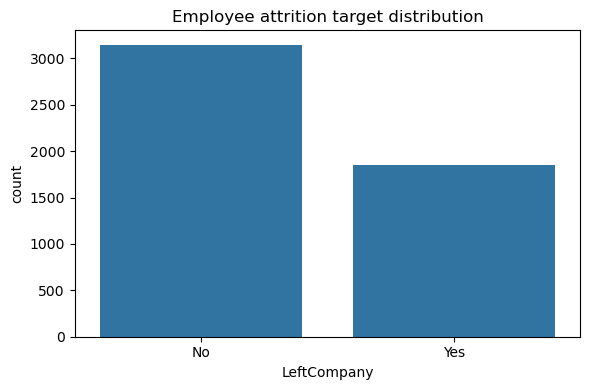

Features: 19
Attrition rate: 37.1 %
Categorical features: ['Gender', 'Department', 'Designation', 'EducationQualification', 'DoesOvertime', 'MaritalStatus', 'City']
Numeric features: ['Age', 'MonthlySalary', 'YearsWithCompany', 'YearsInRole', 'AppraisalRating', 'TrainingHours', 'JobSatisfaction', 'WorkLifeBalance', 'PreviousCompanies', 'DistanceFromHome', 'LeavesTaken', 'JoiningYear']


In [4]:
assert "LeftCompany" in df.columns, "Target column 'LeftCompany' was not found."
df = df.drop_duplicates().copy()
df = df[df["LeftCompany"].isin(["Yes", "No"])].copy()

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="LeftCompany")
plt.title("Employee attrition target distribution")
plt.tight_layout()
plt.show()

# Remove direct identifiers to prevent memorization and privacy leakage.
identifier_cols = [c for c in ["EmployeeID", "FullName"] if c in df.columns]

# Parse joining date and derive a numeric year feature; do not use raw date string.
if "DateOfJoining" in df.columns:
    join_date = pd.to_datetime(df["DateOfJoining"], errors="coerce")
    df["JoiningYear"] = join_date.dt.year
    df = df.drop(columns=["DateOfJoining"])

drop_cols = identifier_cols + ["LeftCompany"]
X = df.drop(columns=drop_cols, errors="ignore")
y = df["LeftCompany"].map({"No": 0, "Yes": 1})

print("Features:", X.shape[1])
print("Attrition rate:", round(y.mean()*100, 2), "%")
print("Categorical features:", X.select_dtypes(include=["object", "category"]).columns.tolist())
print("Numeric features:", X.select_dtypes(include=np.number).columns.tolist())

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 4000 | Test rows: 1000


In [7]:
from pathlib import Path

Path("../outputs").mkdir(parents=True, exist_ok=True)
Path("../reports").mkdir(parents=True, exist_ok=True)

print("Output and report folders are ready.")

Output and report folders are ready.


In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42, max_depth=8),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
}
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
        random_state=42, n_jobs=-1
    )
except ImportError:
    print("XGBoost is not installed. Run the install cell and restart the kernel, or continue with the other models.")

pipelines = {name: Pipeline([("preprocess", preprocessor), ("model", model)]) for name, model in models.items()}
results = []
fitted_models = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }
    results.append(row)
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(results_df.round(4))
results_df.to_csv("../outputs/baseline_model_comparison.csv", index=False)

XGBoost is not installed. Run the install cell and restart the kernel, or continue with the other models.


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.781,0.7923,0.5553,0.6529,0.7514
1,Decision Tree,0.741,0.6739,0.5849,0.6263,0.6947
2,Logistic Regression,0.643,0.5148,0.6577,0.5775,0.6932


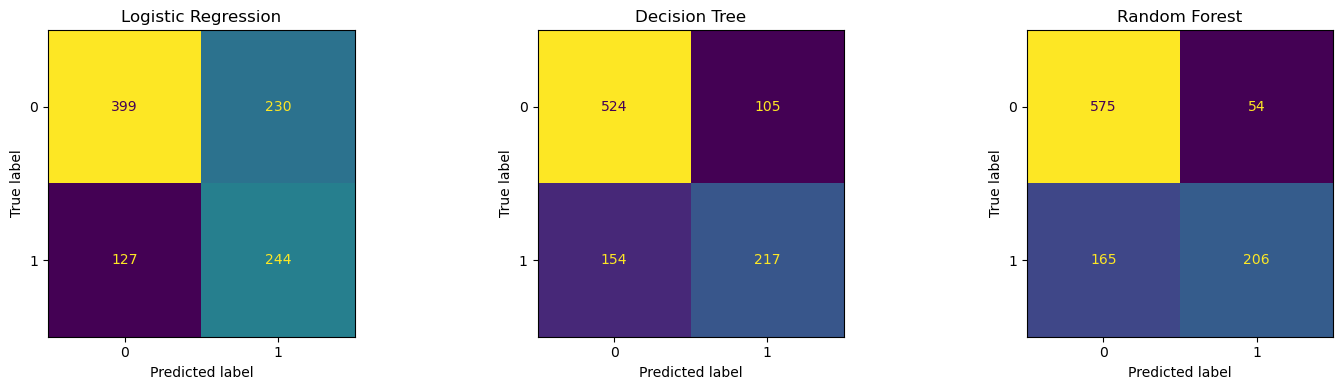

<Figure size 700x600 with 0 Axes>

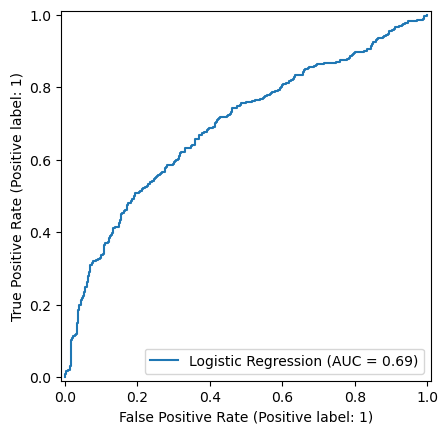

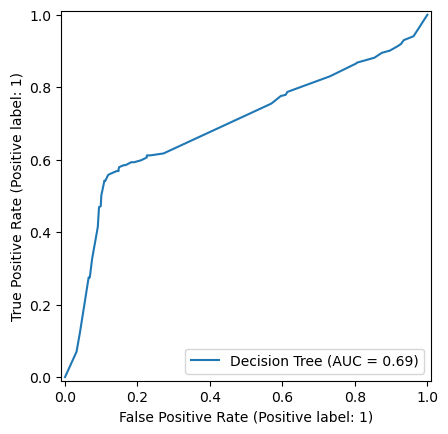

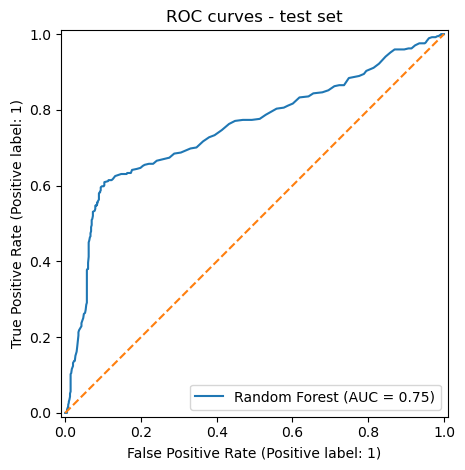

In [9]:
fig, axes = plt.subplots(1, len(fitted_models), figsize=(5*len(fitted_models), 4))
if len(fitted_models) == 1:
    axes = [axes]
for ax, (name, pipe) in zip(axes, fitted_models.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("../outputs/confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7,6))
for name, pipe in fitted_models.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name)
plt.plot([0,1], [0,1], linestyle="--", label="Chance")
plt.title("ROC curves - test set")
plt.tight_layout()
plt.savefig("../outputs/roc_curves.png", dpi=160, bbox_inches="tight")
plt.show()

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy":"accuracy", "precision":"precision", "recall":"recall", "f1":"f1", "roc_auc":"roc_auc"}
cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({
        "Model": name,
        **{f"{metric}_mean": scores[f"test_{metric}"].mean() for metric in scoring},
        **{f"{metric}_std": scores[f"test_{metric}"].std() for metric in scoring}
    })
cv_df = pd.DataFrame(cv_rows).sort_values("roc_auc_mean", ascending=False)
display(cv_df.round(4))
cv_df.to_csv("../outputs/cross_validation_results.csv", index=False)

,Model,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,accuracy_std,precision_std,recall_std,f1_std,roc_auc_std
2,Random Forest,0.8000,0.8251,0.5849,0.6840,0.7706,0.0110,0.0129,0.0329,0.0235,0.0173
1,Decision Tree,0.7397,0.6645,0.6085,0.6345,0.7206,0.0181,0.0336,0.0238,0.0191,0.0149
0,Logistic Regression,0.6468,0.5191,0.6475,0.5759,0.7010,0.0048,0.0047,0.0339,0.0147,0.0108


In [11]:
# RandomizedSearchCV runs on the training data only; the test set remains held out.
param_distributions = {
    "Decision Tree": {
        "model__max_depth": [None, 4, 6, 8, 10, 14],
        "model__min_samples_split": [2, 5, 10, 20],
        "model__min_samples_leaf": [1, 2, 4, 8],
        "model__criterion": ["gini", "entropy", "log_loss"],
    },
    "Random Forest": {
        "model__n_estimators": [150, 250, 400],
        "model__max_depth": [None, 8, 12, 18],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2", 0.7],
    },
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__solver": ["lbfgs"],
        "model__class_weight": [None, "balanced"],
    },
}
tuned = {}
tuning_rows = []
for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:
    estimator = Pipeline([("preprocess", preprocessor), ("model", models[name])])
    search = RandomizedSearchCV(
        estimator, param_distributions[name], n_iter=12, scoring="roc_auc",
        cv=cv, random_state=42, n_jobs=-1, refit=True
    )
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    tuning_rows.append({"Model": name, "Best CV ROC-AUC": search.best_score_, "Best parameters": search.best_params_})

# Tune XGBoost if available
if "XGBoost" in models:
    xgb_params = {
        "model__n_estimators": [150, 250, 400],
        "model__max_depth": [3, 4, 5, 7],
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__subsample": [0.8, 0.9, 1.0],
        "model__colsample_bytree": [0.8, 0.9, 1.0],
    }
    search = RandomizedSearchCV(
        Pipeline([("preprocess", preprocessor), ("model", models["XGBoost"])]),
        xgb_params, n_iter=12, scoring="roc_auc", cv=cv, random_state=42, n_jobs=-1, refit=True
    )
    search.fit(X_train, y_train)
    tuned["XGBoost"] = search.best_estimator_
    tuning_rows.append({"Model": "XGBoost", "Best CV ROC-AUC": search.best_score_, "Best parameters": search.best_params_})

tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df)
tuning_df.to_csv("../outputs/hyperparameter_tuning.csv", index=False)

,Model,Best CV ROC-AUC,Best parameters
0,Logistic Regression,0.703656,"{'model__solver': 'lbfgs', 'model__class_weigh..."
1,Decision Tree,0.758686,"{'model__min_samples_split': 10, 'model__min_s..."
2,Random Forest,0.774134,"{'model__n_estimators': 150, 'model__min_sampl..."


In [12]:
final_rows = []
for name, pipe in tuned.items():
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    final_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })
final_results = pd.DataFrame(final_rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(final_results.round(4))
final_results.to_csv("../outputs/tuned_model_comparison.csv", index=False)

best_name = final_results.iloc[0]["Model"]
best_model = tuned[best_name]
print("Best model by test ROC-AUC:", best_name)
print(classification_report(y_test, best_model.predict(X_test), target_names=["Stayed (No)", "Left (Yes)"]))
joblib.dump(best_model, "../outputs/best_attrition_model.joblib")

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.782,0.7684,0.5903,0.6677,0.7567
1,Decision Tree,0.780,0.7849,0.5606,0.6541,0.7510
2,Logistic Regression,0.644,0.5161,0.6496,0.5752,0.6951


Best model by test ROC-AUC: Random Forest
              precision    recall  f1-score   support

 Stayed (No)       0.79      0.90      0.84       629
  Left (Yes)       0.77      0.59      0.67       371

    accuracy                           0.78      1000
   macro avg       0.78      0.74      0.75      1000
weighted avg       0.78      0.78      0.77      1000



['../outputs/best_attrition_model.joblib']

,Feature,ImportanceMean,ImportanceStd
11,JobSatisfaction,0.0926,0.0145
12,WorkLifeBalance,0.0711,0.0062
8,AppraisalRating,0.0631,0.0055
10,DoesOvertime,0.0628,0.0065
6,YearsWithCompany,0.0086,0.0029
18,JoiningYear,0.0063,0.0026
13,MaritalStatus,0.0035,0.0007
14,PreviousCompanies,0.0030,0.0012
9,TrainingHours,0.0024,0.0019
16,LeavesTaken,0.0021,0.0016


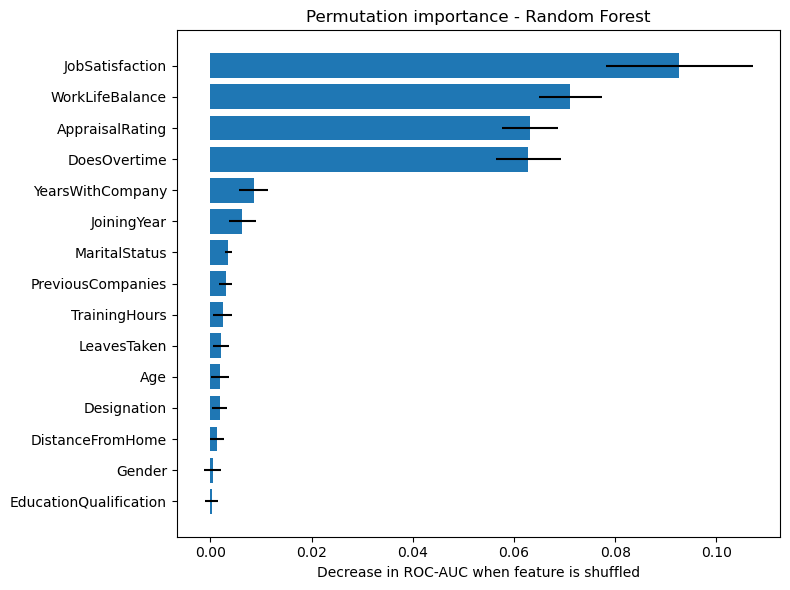

In [13]:
# Permutation importance works with the full pipeline and original feature columns.
perm = permutation_importance(
    best_model, X_test, y_test, scoring="roc_auc",
    n_repeats=8, random_state=42, n_jobs=-1
)
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "ImportanceMean": perm.importances_mean,
    "ImportanceStd": perm.importances_std
}).sort_values("ImportanceMean", ascending=False)
display(importance_df.head(15).round(4))
importance_df.to_csv("../outputs/permutation_feature_importance.csv", index=False)

top = importance_df.head(15).sort_values("ImportanceMean")
plt.figure(figsize=(8,6))
plt.barh(top["Feature"], top["ImportanceMean"], xerr=top["ImportanceStd"])
plt.xlabel("Decrease in ROC-AUC when feature is shuffled")
plt.title(f"Permutation importance - {best_name}")
plt.tight_layout()
plt.savefig("../outputs/feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()

In [14]:
# Build a data-backed short interpretation from the results above.
attrition_rate = y.mean() * 100
top_features = importance_df.head(5)["Feature"].tolist()
report = f'''# Business Interpretation Report: Employee Attrition Prediction

## Dataset overview
- Records used: {len(df):,}
- Input features after removing direct identifiers: {X.shape[1]}
- Observed attrition rate: {attrition_rate:.2f}%
- Target definition: LeftCompany = Yes means the employee left.

## Model selection
The best model by held-out test ROC-AUC in this run was **{best_name}**.
The final metrics are available in `../outputs/tuned_model_comparison.csv`.
Use precision and recall alongside accuracy because the costs of missed attrition and false alerts differ.

## Features to investigate
The top features by permutation importance for this model are: {", ".join(top_features)}.
Permutation importance indicates predictive usefulness in this dataset; it does not prove that a feature causes attrition.

## Suggested HR actions
1. Use model outputs only to guide voluntary, aggregate retention analysis and employee listening—not automated employment decisions.
2. Investigate whether the most predictive factors are actionable and supported by qualitative evidence.
3. Compare error rates and calibration across relevant employee groups before any operational use.
4. Recheck performance on newer data and monitor for drift.

## Limitations
- Dataset patterns may not represent a real organization or future workforce.
- Predictive associations are not causal explanations.
- The model can reflect historical bias and data collection issues.
- Any real deployment requires privacy review, fairness evaluation, and HR/legal oversight.
'''
Path("../reports/business_interpretation_report.md").write_text(report, encoding="utf-8")
print(report)

# Business Interpretation Report: Employee Attrition Prediction

## Dataset overview
- Records used: 5,000
- Input features after removing direct identifiers: 19
- Observed attrition rate: 37.10%
- Target definition: LeftCompany = Yes means the employee left.

## Model selection
The best model by held-out test ROC-AUC in this run was **Random Forest**.
The final metrics are available in `../outputs/tuned_model_comparison.csv`.
Use precision and recall alongside accuracy because the costs of missed attrition and false alerts differ.

## Features to investigate
The top features by permutation importance for this model are: JobSatisfaction, WorkLifeBalance, AppraisalRating, DoesOvertime, YearsWithCompany.
Permutation importance indicates predictive usefulness in this dataset; it does not prove that a feature causes attrition.

## Suggested HR actions
1. Use model outputs only to guide voluntary, aggregate retention analysis and employee listening—not automated employment decisions.
2. Inv

In [15]:
evaluation_report = "# Evaluation Report: Employee Attrition Prediction\n\n"
evaluation_report += "## Baseline model comparison\n\n" + results_df.round(4).to_markdown(index=False) + "\n\n"
evaluation_report += "## Tuned model comparison\n\n" + final_results.round(4).to_markdown(index=False) + "\n\n"
evaluation_report += "## Cross-validation results\n\n" + cv_df.round(4).to_markdown(index=False) + "\n\n"
evaluation_report += "## Notes\n- Test set was held out from model tuning.\n- CV used stratified 5-fold splits on training data.\n- ROC-AUC measures ranking performance, not probability calibration.\n"
Path("../reports/evaluation_report.md").write_text(evaluation_report, encoding="utf-8")
print("Saved evaluation report to ../reports/evaluation_report.md")

Saved evaluation report to ../reports/evaluation_report.md


In [16]:
# Keep a reproducible record of package versions if needed.
import sklearn
print("scikit-learn:", sklearn.__version__)
try:
    import xgboost
    print("xgboost:", xgboost.__version__)
except ImportError:
    print("xgboost: not installed")

scikit-learn: 1.5.1
xgboost: not installed
